In [1]:
import matplotlib.pyplot as plt

# **Section A** - _Training Data Pre-Processing and Analysis_

## 1. Identifying and Handling Missing Values

In [2]:
CATEGORICAL_COLUMNS = ("Attrition", "BusinessTravel", "Department", "Gender", "JobRole", "OverTime")
ORDINAL_COLUMNS = ("EnvironmentSatisfaction", "JobInvolvement", "JobSatisfaction", "WorkLifeBalance")

def read_file(filename):
    """
    Opens a file and returns an array (two-dimensional if 2+ columns).
    Splits lines by comma and trims any leading or trailing whitespaces.
    """

    with open(filename) as file:
        lines = file.read().splitlines()

        # check if further processing for 2d arrays is required
        if "," in lines[0]:
            for k, v in enumerate(lines):
                split_line = v.split(",")

                for i, entry in enumerate(split_line):
                    entry = entry.strip()
                    try:
                        entry = float(entry)
                    except ValueError:
                        pass
                    split_line[i] = entry

                lines[k] = split_line

        return lines


def fix_data(data, headers):
    print(f"Initial number of rows: {len(data)}")

    averages = {}
    change = {}  # mark specific entries to change to avoid unnecessary comparisons

    remove = set()

    for index, header in enumerate(headers):

        categorical = header in CATEGORICAL_COLUMNS

        missing_values = 0

        running_total = 0
        included_entries = 0

        for row_index, row in enumerate(data):
            if row[index] == "":
                missing_values += 1

                if categorical:
                    remove.add(row_index)
                else:
                    if header not in change:
                        change[header] = []

                    change[header].append(row)

            elif not categorical:
                running_total += row[index]
                included_entries += 1

        if missing_values > 0:
            print(f"{header}: {missing_values} values missing ({'rows removed' if categorical else 'imputed'})")

            if not categorical:
                average = running_total / included_entries

                if header in ORDINAL_COLUMNS:
                    average = int(round(average))  # ordinal values cannot be decimal

                averages[header] = average

    removed = 0
    for index in range(len(data)):
        if index in remove:
            del data[index - removed]
            removed += 1
    print(f"Rows removed due to categorical missing values: {removed}")

    headers_to_change = list(change.keys())

    for header in headers_to_change:
        average = averages[header]
        index = headers.index(header)

        for row in change[header]:
            row[index] = average

    print(f"Remaining number of rows: {len(data)}")

    # verify everything has been imputed/removed
    for row in data:
        assert "" not in row, "Value missing from fixed data!"

    print("\nConfirmed: No missing values remain in the dataset.")


data = read_file("train.csv")
headers = data.pop(0)

fix_data(data, headers)


Initial number of rows: 1029
Age: 64 values missing (imputed)
Attrition: 53 values missing (rows removed)
BusinessTravel: 44 values missing (rows removed)
Department: 51 values missing (rows removed)
DistanceFromHome: 53 values missing (imputed)
EnvironmentSatisfaction: 52 values missing (imputed)
Gender: 49 values missing (rows removed)
JobInvolvement: 67 values missing (imputed)
JobRole: 50 values missing (rows removed)
JobSatisfaction: 47 values missing (imputed)
NumCompaniesWorked: 55 values missing (imputed)
MonthlyIncome: 65 values missing (imputed)
OverTime: 36 values missing (rows removed)
PercentSalaryHike: 54 values missing (imputed)
WorkLifeBalance: 59 values missing (imputed)
YearsAtCompany: 34 values missing (imputed)
YearsInCurrentRole: 39 values missing (imputed)
YearsSinceLastPromotion: 52 values missing (imputed)
Rows removed due to categorical missing values: 259
Remaining number of rows: 770

Confirmed: No missing values remain in the dataset.


## 2. Analyzing Attrition Distribution by Age (Bar Chart)

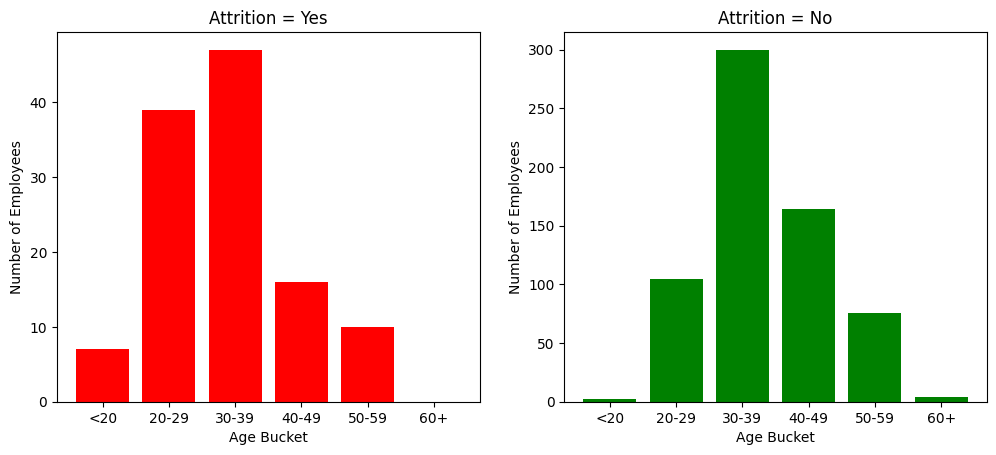

In [57]:
buckets = ("<20", "20-29", "30-39", "40-49", "50-59", "60+")
fig, ax = plt.subplots(1, 2)
fig.set_figwidth(12)  # set spacing so graphs aren't squished

attrition_index = headers.index("Attrition")
age_index = headers.index("Age")

attrition_groups = [[], []]


for entry in data:
    if entry[attrition_index] == "Yes":
        attrition_groups[0].append(entry)
    else:
        attrition_groups[1].append(entry)


for key, value in enumerate(("Yes", "No")):
    ax[key].set_title(f"Attrition = {value}")
    ax[key].set(ylabel="Number of Employees", xlabel="Age Bucket")

    group = attrition_groups[key].copy()

    # setup bucket bounds
    lower_bound = 0
    upper_bound = 20

    bucket_counts = []  # the # of entries in each bucket

    for i in range(5):  # repeat for every bucket that has x-y range

        running_total = 0

        for j in range(len(group) -1, -1, -1):

            entry = group[j]

            if lower_bound <= entry[age_index] < upper_bound:
                running_total += 1
                del group[j]

        bucket_counts.append(running_total)

        lower_bound = upper_bound
        upper_bound += 10

    bucket_counts.append(len(group))  # all remaining entries will be 60+ years of age

    ax[key].bar(buckets, bucket_counts, color=("Red", "Green")[key])


## 3. Analyzing Attrition Among Employees based on Job Satisfaction (Pie Chart)

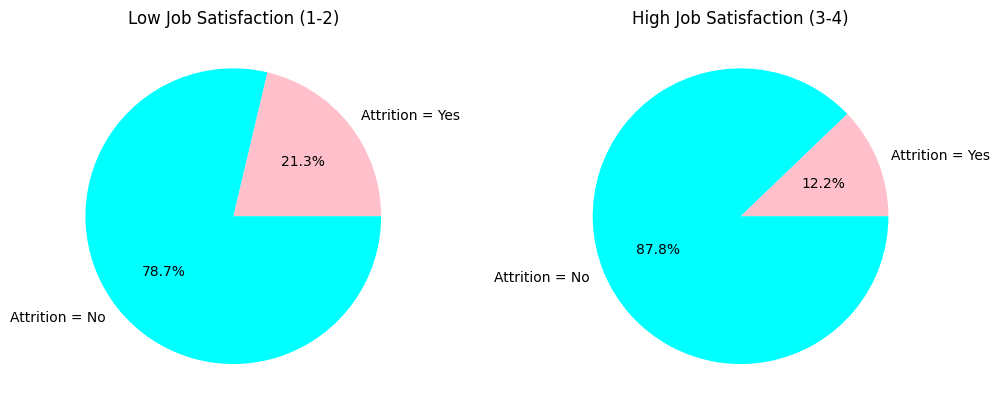

In [55]:
satisfaction_index = headers.index("JobSatisfaction")

satisfactions = ("Low Job Satisfaction (1-2)", "High Job Satisfaction (3-4)")
satisfaction_groups = [[], []]

fig, ax = plt.subplots(1, 2)
fig.set_figwidth(12)

for entry in data:
    if entry[satisfaction_index] <= 2:
        satisfaction_groups[0].append(entry)
    else:
        satisfaction_groups[1].append(entry)

for key, value in enumerate(satisfactions):
    plot = ax[key]
    plot.set_title(value)

    group = satisfaction_groups[key]

    attrition = [0, 0]  # 0th yes, 1st no

    for entry in group:
        attrition[0 if entry[attrition_index] == "Yes" else 1] += 1

    plot.pie(attrition, labels=("Attrition = Yes", "Attrition = No"), colors=("Pink", "Aqua"), autopct='%1.1f%%')



## 4. Checking for Class Imbalance in the Training Data

In [59]:
print(f"Number of employees who quit (Attrition=Yes): {len(attrition_groups[0])}")  # use sorted lists from earlier (1.2)
print(f"Number of employees who quit (Attrition=No): {len(attrition_groups[1])}")

Number of employees who quit (Attrition=Yes): 119
Number of employees who quit (Attrition=No): 651


# **Section B** - _Building the Decision Tree Classifier_